In [1]:
import sys, subprocess, shutil, importlib, os, platform, time, json, re, math, glob, warnings
warnings.filterwarnings("ignore")
T_NOTEBOOK_START = time.perf_counter()

def _ensure(pkg_spec, module):
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg_spec], check=True)

PYSPARK_VERSION = "3.5.9"
_ensure(f"pyspark=={PYSPARK_VERSION}", "pyspark")
_ensure("nltk", "nltk")
if shutil.which("java") is None:
    subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jre-headless", shell=True, check=True)

import pyspark
if pyspark.__version__ != PYSPARK_VERSION:
    print(f"PERINGATAN: PySpark terpasang {pyspark.__version__}, notebook diuji dengan {PYSPARK_VERSION}")
print("Python :", platform.python_version())
print("PySpark:", pyspark.__version__)

PERINGATAN: PySpark terpasang 4.0.4, notebook diuji dengan 3.5.9
Python : 3.13.16
PySpark: 4.0.4


In [2]:
SEED            = 42                 # seed tetap untuk semua proses acak/pembagian data
CSV_PATH        = os.environ.get("MAHADATA_CSV")   # isi manual bila CSV sudah ada di disk
DATA_SOURCE     = "kagglehub"        # "kagglehub" | "upload" | "drive"
DRIVE_PATH      = "/content/drive/MyDrive/Amazon_Unlocked_Mobile.csv"

SAMPLE_FRAC     = 1.0                # 1.0 = seluruh data; kecilkan (mis. 0.05) untuk uji cepat
TRAIN_FRAC      = 0.75               # sama dengan artikel: 75% latih, 25% uji
SUCCESS_RATING  = 4                  # rating >= 4 dianggap "sukses" (deviasi: artikel tidak mendefinisikan)
FIG_THRESHOLDS  = [0.5, 0.25, 0.1]   # ambang pada |ΔG| ternormalisasi; 0.5 = ambang artikel
N_PARTITIONS    = 8

RUN_SCALABILITY = True               # eksperimen waktu vs ukuran data (analog Gambar 3 artikel)
SCAL_FRACS      = [0.25, 0.5, 0.75, 1.0]

OUT_DIR = "/content/hasil_eksperimen" if os.path.isdir("/content") else os.path.abspath("hasil_eksperimen")
os.makedirs(OUT_DIR, exist_ok=True)
print("Folder keluaran:", OUT_DIR)

Folder keluaran: /content/hasil_eksperimen


In [3]:
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel

mem_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
driver_mem = f"{max(2, int(mem_gb * 0.6))}g"

spark = (SparkSession.builder.master("local[*]").appName("Mahadata-DMRDF")
         .config("spark.driver.memory", driver_mem)
         .config("spark.sql.shuffle.partitions", str(N_PARTITIONS))
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
spark.range(1000).count()   # pemanasan JVM agar pengukuran waktu tidak bias

_jv = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
ENV = {
    "python": platform.python_version(),
    "pyspark": pyspark.__version__,
    "spark": spark.version,
    "java": next((l for l in _jv if "version" in l), _jv[0] if _jv else "?"),
    "os": platform.platform(),
    "cpu_cores": os.cpu_count(),
    "ram_gb": round(mem_gb, 1),
    "driver_memory": driver_mem,
    "master": sc.master,
    "seed": SEED,
}
for k, v in ENV.items():
    print(f"{k:14s}: {v}")

python        : 3.13.16
pyspark       : 4.0.4
spark         : 4.0.4
java          : openjdk version "21.0.12.1" 2026-08-18
os            : Linux-6.6.122+-x86_64-with-glibc2.39
cpu_cores     : 2
ram_gb        : 12.7
driver_memory : 7g
master        : local[*]
seed          : 42


In [4]:
def find_csv():
    if CSV_PATH and os.path.exists(CSV_PATH):
        return CSV_PATH
    if DATA_SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        return DRIVE_PATH
    if DATA_SOURCE == "upload":
        from google.colab import files
        up = files.upload()
        return list(up.keys())[0]
    _ensure("kagglehub", "kagglehub")
    import kagglehub
    p = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")
    cands = glob.glob(os.path.join(p, "**", "*.csv"), recursive=True)
    if not cands:
        raise FileNotFoundError(f"Tidak ada CSV di {p}")
    cands.sort(key=lambda x: ("unlocked" not in x.lower(), x))
    return cands[0]

csv_path = find_csv()
print("CSV:", csv_path, f"({os.path.getsize(csv_path)/2**20:.1f} MB)")

100%|██████████| 32.6M/32.6M [00:02<00:00, 11.5MB/s]

Extracting files...


CSV: /root/.cache/kagglehub/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones/versions/1/Amazon_Unlocked_Mobile.csv (125.8 MB)


In [5]:
raw = spark.read.csv(csv_path, header=True, multiLine=True, escape='"', quote='"')
expected = {"Product Name", "Brand Name", "Price", "Rating", "Reviews", "Review Votes"}
missing = expected - set(raw.columns)
if missing:
    raise ValueError(f"Kolom CSV tidak sesuai skema Kaggle PromptCloudHQ; hilang: {missing}; ada: {raw.columns}")

n_raw = raw.count()
base = (raw.select(F.col("Product Name").alias("product"),
                   F.col("Brand Name").alias("brand"),
                   F.col("Rating").cast("int").alias("rating"),
                   F.col("Reviews").alias("review"))
        .where(F.col("rating").between(1, 5)
               & F.col("review").isNotNull()
               & (F.length(F.trim(F.col("review"))) > 0)))
n_clean = base.count()
print(f"Baris mentah: {n_raw:,} | setelah pembersihan: {n_clean:,} | dibuang: {n_raw-n_clean:,}")

if SAMPLE_FRAC < 1.0:
    base = base.sample(False, SAMPLE_FRAC, SEED)

# id baris deterministik (pembacaan multiLine = 1 partisi, jadi urutan stabil)
schema = T.StructType([T.StructField("id", T.LongType()), T.StructField("product", T.StringType()),
                       T.StructField("brand", T.StringType()), T.StructField("rating", T.IntegerType()),
                       T.StructField("review", T.StringType())])
rdd_id = base.rdd.zipWithIndex().map(lambda x: (int(x[1]), x[0]["product"], x[0]["brand"], x[0]["rating"], x[0]["review"]))
df = (spark.createDataFrame(rdd_id, schema)
      .withColumn("label", (F.col("rating") >= SUCCESS_RATING).cast("double"))
      .repartition(N_PARTITIONS).persist(StorageLevel.MEMORY_AND_DISK))
N_DF = df.count()
print(f"Jumlah ulasan dipakai: {N_DF:,}")

Baris mentah: 413,840 | setelah pembersihan: 413,778 | dibuang: 62
Jumlah ulasan dipakai: 413,778


 rating  count  persen
      1  72337   17.48
      2  24724    5.98
      3  31763    7.68
      4  61374   14.83
      5 223580   54.03

Proporsi kelas sukses (rating>=4): 0.6887  -> baseline mayoritas = 0.6887

10 merek terbanyak:
      brand  count
   Samsung  65728
      None  65155
       BLU  63246
     Apple  58179
        LG  22410
BlackBerry  16872
     Nokia  16805
  Motorola  13417
       HTC  12724
     CNPGD  12613

Jumlah merek unik: 385
Panjang ulasan (karakter): {'count': '413778', 'mean': '216.70659145725486', 'stddev': '463.6001022601473', 'min': '1', 'max': '29419'}


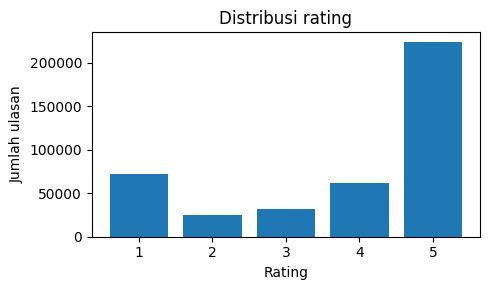

In [6]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)

rating_dist = df.groupBy("rating").count().orderBy("rating").toPandas()
rating_dist["persen"] = (rating_dist["count"] / N_DF * 100).round(2)
print(rating_dist.to_string(index=False))

p_success = df.agg(F.avg("label")).first()[0]
print(f"\nProporsi kelas sukses (rating>={SUCCESS_RATING}): {p_success:.4f}  -> baseline mayoritas = {max(p_success, 1-p_success):.4f}")

brands = df.groupBy("brand").count().orderBy(F.desc("count")).limit(10).toPandas()
print("\n10 merek terbanyak:\n", brands.to_string(index=False))
print("\nJumlah merek unik:", df.select("brand").distinct().count())
print("Panjang ulasan (karakter):", df.select(F.length("review").alias("n")).describe().toPandas().set_index("summary")["n"].to_dict())

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(rating_dist["rating"].astype(str), rating_dist["count"])
ax.set_xlabel("Rating"); ax.set_ylabel("Jumlah ulasan"); ax.set_title("Distribusi rating")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_distribusi_rating.png", dpi=150); plt.show()

STATS = {"n_raw": n_raw, "n_clean": n_clean, "n_used": N_DF, "p_success": p_success,
         "majority_baseline": max(p_success, 1 - p_success), "sample_frac": SAMPLE_FRAC}

In [7]:
rdd_demo = df.rdd.map(lambda r: (r["rating"], len(r["review"])))
print("first()                :", rdd_demo.first())
print("takeOrdered(3) terpanjang:", rdd_demo.takeOrdered(3, key=lambda x: -x[1]))
print("reduce() total karakter :", rdd_demo.map(lambda x: x[1]).reduce(lambda a, b: a + b))
print("filter+count rating 5   :", rdd_demo.filter(lambda x: x[0] == 5).count())
print("reduceByKey per rating  :", sorted(rdd_demo.map(lambda x: (x[0], 1)).reduceByKey(lambda a, b: a + b).collect()))

first()                : (5, 59)
takeOrdered(3) terpanjang: [(5, 29419), (5, 29419), (5, 27777)]
reduce() total karakter : 89668420
filter+count rating 5   : 223580
reduceByKey per rating  : [(1, 72337), (2, 24724), (3, 31763), (4, 61374), (5, 223580)]


In [8]:
import nltk
from collections import defaultdict
for _r in ("wordnet", "sentiwordnet"):
    try:
        nltk.download(_r, quiet=True)
    except Exception as e:
        print("Unduh NLTK gagal:", _r, e)
from nltk.corpus import sentiwordnet as swn

_acc = defaultdict(list)
for s in swn.all_senti_synsets():
    if s.obj_score() >= 1.0:
        continue
    sc_ = s.pos_score() - s.neg_score()
    for name in s.synset.lemma_names():
        if "_" not in name:
            _acc[name.lower()].append(sc_)
LEX = {w: sum(v) / len(v) for w, v in _acc.items()}
bc_lex = sc.broadcast(LEX)
print(f"Leksikon SentiWordNet: {len(LEX):,} kata")

ASPECTS = {
    "battery":   r"\bbatter(?:y|ies)\b|\bcharg\w*",
    "price":     r"\bpric\w*|\bcost\w*|\bcheap\w*|\bexpensive\b|\bworth\b|\bvalue\b|\bmoney\b|\bafford\w*|\bbargain\b",
    "camera":    r"\bcamera\w*|\bphoto\w*|\bpictures?\b|\bpics?\b|\blens\b|\bselfies?\b|\bvideo\w*",
    "screen":    r"\bscreens?\b|\bdisplay\w*|\btouch\w*|\bresolution\b|\bbright\w*",
    "storage":   r"\bstorage\b|\bmemory\b|\binternal\b|\bsd\s?cards?\b|\bgb\b",
    "ram":       r"\bram\b",
    "processor": r"\bprocessor\w*|\bcpu\b|\bspeed\b|\bfast\b|\bslow\w*|\blag\w*|\bperformance\b|\bfreez\w*|\bsmooth\w*",
    "weight":    r"\bweigh\w*|\bheav\w*|\blightweight\b",
    "sound":     r"\bsounds?\b|\bspeakers?\b|\bvolume\b|\baudio\b|\bringtones?\b|\bheadphones?\b|\bearphones?\b|\bloud\b",
    "signal":    r"\bsignals?\b|\bnetwork\w*|\breception\b|\bwi-?fi\b|\bbluetooth\b|\b[345]g\b|\blte\b|\bgsm\b|\bcarriers?\b|\bcoverage\b",
    "sim":       r"\bsim\b|\bunlock\w*|\bdual\b",
    "size":      r"\bsize\b|\bsmall\b|\bbig\b|\blarge\b|\bcompact\b|\bbulky\b",
    "design":    r"\bdesign\w*|\blooks?\b|\bcolou?rs?\b|\bbuild\b|\bsturdy\b|\bcase\b|\bstyle\b|\bsleek\b",
    "os":        r"\bandroid\b|\bios\b|\bsoftware\b|\bupdates?\b|\bapps?\b|\bos\b|\bwindows\b",
    "service":   r"\bwarranty\b|\brefund\w*|\bseller\b|\bshipping\b|\bshipped\b|\bdelivery\b|\bpackag\w*|\barrived\b",
    "call":      r"\bcalls?\b|\bcalling\b|\bvoice\b|\btexts?\b|\btexting\b|\bmessag\w*|\bkeyboard\b",
}
ASPECT_NAMES = list(ASPECTS)
K = len(ASPECT_NAMES)
ASPECT_RX = [re.compile(ASPECTS[a]) for a in ASPECT_NAMES]
NEG = {"not", "no", "never", "cannot", "cant", "dont", "didnt", "doesnt", "isnt", "wasnt", "wont",
       "wouldnt", "couldnt", "hardly", "without"}
SENT_SPLIT = re.compile(r"[.!?;\n]+")
TOK = re.compile(r"[a-z']+")

def _polarity(tokens, lex):
    tot = 0.0
    for i, t in enumerate(tokens):
        s = lex.get(t)
        if s is None:
            continue
        if any((w in NEG) or w.endswith("n't") for w in tokens[max(0, i - 3):i]):
            s = -s
        tot += s
    return tot

def analyze(text):
    lex = bc_lex.value
    t = (text or "").lower().replace("’", "'")
    pres = [0.0] * K
    pol = [0.0] * K
    tot = 0.0
    for sent in SENT_SPLIT.split(t):
        if not sent.strip():
            continue
        sp = _polarity(TOK.findall(sent), lex)
        tot += sp
        for k, rx in enumerate(ASPECT_RX):
            if rx.search(sent):
                pres[k] = 1.0
                pol[k] += sp
    return [math.tanh(tot)] + pres + [math.tanh(x) for x in pol]

feat_udf = F.udf(analyze, T.ArrayType(T.DoubleType()))
FEAT_COLS = ["O"] + [f"p_{a}" for a in ASPECT_NAMES] + [f"s_{a}" for a in ASPECT_NAMES]

def build_features(df_in):
    out = (df_in.withColumn("_f", feat_udf("review"))
           .select("id", "product", "review", "rating", "label",
                   *[F.col("_f")[i].alias(c) for i, c in enumerate(FEAT_COLS)])
           .persist(StorageLevel.MEMORY_AND_DISK))
    n = out.count()   # memicu komputasi + cache
    return out, n

t0 = time.perf_counter()
dfa, N_FEAT = build_features(df)
T_FEAT_FULL = time.perf_counter() - t0
print(f"Fitur dihitung untuk {N_FEAT:,} ulasan dalam {T_FEAT_FULL:.1f} s")
cov = dfa.select([F.avg(f"p_{a}").alias(a) for a in ASPECT_NAMES]).first().asDict()
print("Cakupan aspek (proporsi ulasan yang menyebut aspek):")
print(pd.Series(cov).sort_values(ascending=False).round(4).to_string())

Leksikon SentiWordNet: 30,821 kata
Fitur dihitung untuk 413,778 ulasan dalam 101.9 s
Cakupan aspek (proporsi ulasan yang menyebut aspek):
price        0.1593
battery      0.1401
screen       0.1187
processor    0.1116
service      0.1101
os           0.1057
camera       0.1018
design       0.1001
sim          0.0952
signal       0.0896
call         0.0795
size         0.0727
sound        0.0578
storage      0.0398
weight       0.0169
ram          0.0080


In [9]:
def _norm_text(t):
    return re.sub(r"\W+", " ", (t or "").lower()).strip()

def dmrdf_dedup(d):
    keep = (d.rdd.map(lambda r: ((r["product"], _norm_text(r["review"])), r["id"]))
                 .reduceByKey(min)                       # pertahankan kemunculan pertama
                 .map(lambda kv: (kv[1],)))
    keep_df = spark.createDataFrame(keep, T.StructType([T.StructField("id", T.LongType())]))
    return d.join(keep_df, "id", "inner")

def split_train_test(d):
    # pembagian deterministik berbasis hash id (stabil antar konfigurasi dan antar jalan)
    b = F.pmod(F.hash(F.col("id"), F.lit(SEED)), F.lit(100))
    cut = int(TRAIN_FRAC * 100)
    return d.where(b < cut), d.where(b >= cut)

def compute_fig(train):
    N = train.count()
    aggs = []
    for a in ASPECT_NAMES:
        p = F.col(f"p_{a}")
        aggs += [F.sum(p).alias(f"n_{a}"),
                 F.sum(p * F.col("O")).alias(f"sO_{a}"),
                 F.sum(p * F.col("rating")).alias(f"sS_{a}"),
                 F.sum(p * F.abs(F.col("O")) * F.col("rating")).alias(f"sOS_{a}")]
    r = train.agg(*aggs).first().asDict()
    rows = []
    for a in ASPECT_NAMES:
        n = r[f"n_{a}"] or 0.0
        if n <= 0:
            rows.append((a, 0, 0.0, 0.0, 0.0, 0.0)); continue
        P = n / N
        E = -P * math.log2(1 / P) * r[f"sOS_{a}"]                 # Pers. (1)+(2)
        R = -n * P * math.log2(abs(E)) if abs(E) > 0 else 0.0     # Pers. (3) dengan |E_f|
        dG = R - (E / N) * (r[f"sO_{a}"] - r[f"sS_{a}"])          # Pers. (4)
        rows.append((a, int(n), P, E, R, dG))
    fig = pd.DataFrame(rows, columns=["aspek", "n_ulasan", "P", "E_f", "R_I", "delta_G"])
    mx = fig["delta_G"].abs().max()
    fig["norm_absG"] = fig["delta_G"].abs() / mx if mx > 0 else 0.0
    return fig.sort_values("norm_absG", ascending=False).reset_index(drop=True)

def add_delta(d, fig, selected):
    w = {a: float(abs(fig.loc[fig.aspek == a, "delta_G"].iloc[0])) for a in selected}
    tot = sum(w.values())
    expr = F.lit(0.0)
    for a in selected:
        expr = expr + F.col(f"p_{a}") * F.lit(w[a] / tot)
    return d.withColumn("delta", expr)
print("Fungsi DMRDF/FIG siap.")

Fungsi DMRDF/FIG siap.


In [10]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression, LinearSVC
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def train_eval(train, test, feat_cols, tag):
    asm = VectorAssembler(inputCols=feat_cols, outputCol="features", handleInvalid="keep")
    tr = asm.transform(train).select("features", "label").persist(StorageLevel.MEMORY_AND_DISK)
    te = asm.transform(test).select("features", "label").persist(StorageLevel.MEMORY_AND_DISK)
    n_tr, n_te = tr.count(), te.count()
    p1_te = te.agg(F.avg("label")).first()[0]
    out = []
    models = [("LogisticRegression", LogisticRegression(maxIter=100, regParam=0.0, standardization=True)),
              ("LinearSVC", LinearSVC(maxIter=100, regParam=0.01, standardization=True))]
    for name, est in models:
        t = time.perf_counter()
        model = est.fit(tr)
        fit_s = time.perf_counter() - t
        pred = model.transform(te)
        cm = {(r["label"], r["prediction"]): r["count"] for r in pred.groupBy("label", "prediction").count().collect()}
        tp, tn = cm.get((1.0, 1.0), 0), cm.get((0.0, 0.0), 0)
        fp, fn = cm.get((0.0, 1.0), 0), cm.get((1.0, 0.0), 0)
        tot = tp + tn + fp + fn
        prec = tp / (tp + fp) if (tp + fp) else float("nan")
        rec = tp / (tp + fn) if (tp + fn) else float("nan")
        f1 = 2 * prec * rec / (prec + rec) if (prec == prec and rec == rec and (prec + rec) > 0) else float("nan")
        try:
            auc = BinaryClassificationEvaluator(metricName="areaUnderROC").evaluate(pred)
        except Exception:
            auc = float("nan")
        out.append({"konfigurasi": tag, "model": name, "n_latih": n_tr, "n_uji": n_te, "n_fitur": len(feat_cols),
                    "akurasi": (tp + tn) / tot if tot else float("nan"), "presisi": prec, "recall": rec, "f1": f1, "auc": auc,
                    "baseline_mayoritas": max(p1_te, 1 - p1_te), "tp": tp, "tn": tn, "fp": fp, "fn": fn,
                    "waktu_latih_s": fit_s})
    tr.unpersist(); te.unpersist()
    return out

def run_config(tag, dfa_in, dedup, thr, delta_filter):
    """Satu konfigurasi eksperimen. thr=None -> semua aspek (tanpa seleksi FIG)."""
    times, info = {}, {"konfigurasi": tag, "dedup": dedup, "ambang_FIG": thr, "filter_delta": delta_filter}
    n_in = dfa_in.count()
    d = dfa_in
    if dedup:
        t = time.perf_counter(); d = dmrdf_dedup(dfa_in).persist(StorageLevel.MEMORY_AND_DISK); n_dd = d.count()
        times["dedup_s"] = time.perf_counter() - t
        info["n_duplikat_dibuang"] = n_in - n_dd
    train, test = split_train_test(d)
    fig = None
    if thr is None:
        selected = ASPECT_NAMES
    else:
        t = time.perf_counter(); fig = compute_fig(train); times["fig_s"] = time.perf_counter() - t
        selected = fig.loc[fig.norm_absG >= thr, "aspek"].tolist()
    info["aspek_terpilih"] = selected
    if len(selected) == 0:
        print(f"[{tag}] tidak ada aspek lolos ambang -> dilewati")
        return [], info, times, fig
    if delta_filter and thr is not None:
        train = add_delta(train, fig, selected).where(F.col("delta") > 0)
        test = add_delta(test, fig, selected).where(F.col("delta") > 0)
    cols = [f"p_{a}" for a in selected] + [f"s_{a}" for a in selected]
    t = time.perf_counter(); res = train_eval(train, test, cols, tag); times["latih_eval_s"] = time.perf_counter() - t
    for r in res:
        r.update({"dedup": dedup, "ambang_FIG": thr, "aspek_terpilih": ",".join(selected)})
    if dedup:
        d.unpersist()
    return res, info, times, fig
print("Fungsi pelatihan siap.")

Fungsi pelatihan siap.


In [11]:
CONFIGS = [("A. Tanpa DMRDF/FIG", False, None, False),
           ("B. Dedup saja", True, None, False),
           (f"C. FIG saja (τ={FIG_THRESHOLDS[0]})", False, FIG_THRESHOLDS[0], False)]
CONFIGS += [(f"D. DMRDF+FIG (τ={t})", True, t, True) for t in FIG_THRESHOLDS]

ALL_RESULTS, CONFIG_INFO, STAGE_TIMES, FIG_TABLES = [], {}, {}, {}
for tag, dd, thr, dfilt in CONFIGS:
    print(f"\n=== {tag} ===")
    res, info, times, fig = run_config(tag, dfa, dd, thr, dfilt)
    ALL_RESULTS += res; CONFIG_INFO[tag] = info; STAGE_TIMES[tag] = times
    if fig is not None:
        FIG_TABLES[tag] = fig
    print("aspek terpilih:", info["aspek_terpilih"], "| duplikat dibuang:", info.get("n_duplikat_dibuang", "-"))
    for r in res:
        print(f"  {r['model']:19s} akurasi={r['akurasi']:.4f} presisi={r['presisi']:.4f} recall={r['recall']:.4f} "
              f"f1={r['f1']:.4f} auc={r['auc']:.4f} | baseline={r['baseline_mayoritas']:.4f} | n_uji={r['n_uji']:,}")

RES = pd.DataFrame(ALL_RESULTS)
cols_show = ["konfigurasi", "model", "n_latih", "n_uji", "n_fitur", "akurasi", "presisi", "recall", "f1", "auc", "baseline_mayoritas"]
print("\nRINGKASAN ABLASI")
print(RES[cols_show].round(4).to_string(index=False))


=== A. Tanpa DMRDF/FIG ===
aspek terpilih: ['battery', 'price', 'camera', 'screen', 'storage', 'ram', 'processor', 'weight', 'sound', 'signal', 'sim', 'size', 'design', 'os', 'service', 'call'] | duplikat dibuang: -
  LogisticRegression  akurasi=0.7399 presisi=0.7466 recall=0.9416 f1=0.8329 auc=0.7314 | baseline=0.6881 | n_uji=103,281
  LinearSVC           akurasi=0.7375 presisi=0.7495 recall=0.9290 f1=0.8297 auc=0.7309 | baseline=0.6881 | n_uji=103,281

=== B. Dedup saja ===
aspek terpilih: ['battery', 'price', 'camera', 'screen', 'storage', 'ram', 'processor', 'weight', 'sound', 'signal', 'sim', 'size', 'design', 'os', 'service', 'call'] | duplikat dibuang: 87219
  LogisticRegression  akurasi=0.7278 presisi=0.7326 recall=0.9331 f1=0.8208 auc=0.7300 | baseline=0.6680 | n_uji=81,611
  LinearSVC           akurasi=0.7214 presisi=0.7297 recall=0.9261 f1=0.8162 auc=0.7290 | baseline=0.6680 | n_uji=81,611

=== C. FIG saja (τ=0.5) ===
aspek terpilih: ['price', 'battery', 'screen'] | duplika

Tabel FIG (data latih, konfigurasi: C. FIG saja (τ=0.5))
    aspek  n_ulasan      P      E_f       R_I   delta_G  norm_absG
    price     49608 0.1598 -64070.4 -126555.0 -161117.6     1.0000
  battery     43606 0.1404 -43289.3  -94320.1 -113931.7     0.7071
   screen     36882 0.1188 -37155.7  -66509.0  -80758.3     0.5012
processor     34743 0.1119 -37171.0  -59020.5  -73605.7     0.4568
  service     34175 0.1101 -31864.9  -56270.7  -67962.4     0.4218
       os     32835 0.1057 -32717.4  -52076.7  -63991.1     0.3972
   camera     31763 0.1023 -33183.5  -48798.1  -60612.3     0.3762
   design     31136 0.1003 -32042.8  -46733.0  -58169.6     0.3610
      sim     29647 0.0955 -24365.1  -41251.4  -48953.3     0.3038
   signal     27802 0.0895 -22979.0  -36066.5  -42847.8     0.2659
     call     24684 0.0795 -18335.2  -27791.3  -32376.6     0.2010
     size     22444 0.0723 -19095.1  -23071.2  -28122.4     0.1745
    sound     18089 0.0583 -11826.5  -14258.1  -16473.2     0.1022
  sto

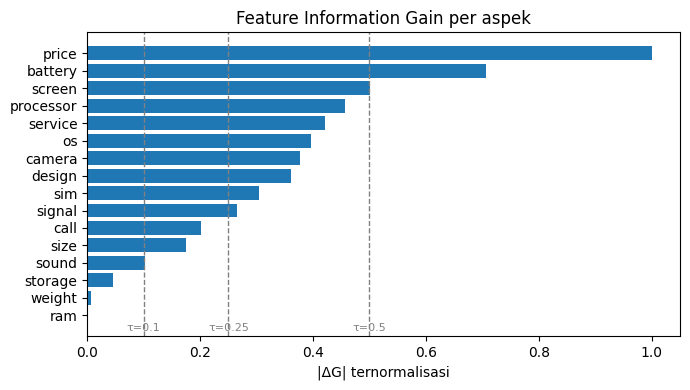

Korelasi Spearman antara frekuensi aspek dan |ΔG|: 1.000


In [12]:
first_fig_tag = next(iter(FIG_TABLES))
fig_tbl = FIG_TABLES[first_fig_tag]
print(f"Tabel FIG (data latih, konfigurasi: {first_fig_tag})")
print(fig_tbl.assign(P=fig_tbl.P.round(4), E_f=fig_tbl.E_f.round(1), R_I=fig_tbl.R_I.round(1),
                     delta_G=fig_tbl.delta_G.round(1), norm_absG=fig_tbl.norm_absG.round(4)).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(fig_tbl["aspek"][::-1], fig_tbl["norm_absG"][::-1])
for thr in FIG_THRESHOLDS:
    ax.axvline(thr, ls="--", lw=1, color="gray")
    ax.text(thr, -0.9, f"τ={thr}", fontsize=8, ha="center", color="gray")
ax.set_xlabel("|ΔG| ternormalisasi"); ax.set_title("Feature Information Gain per aspek")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_fig_per_aspek.png", dpi=150); plt.show()

# apakah ΔG hanya cerminan frekuensi aspek? (korelasi peringkat)
rho = fig_tbl[["n_ulasan", "norm_absG"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman antara frekuensi aspek dan |ΔG|: {rho:.3f}")

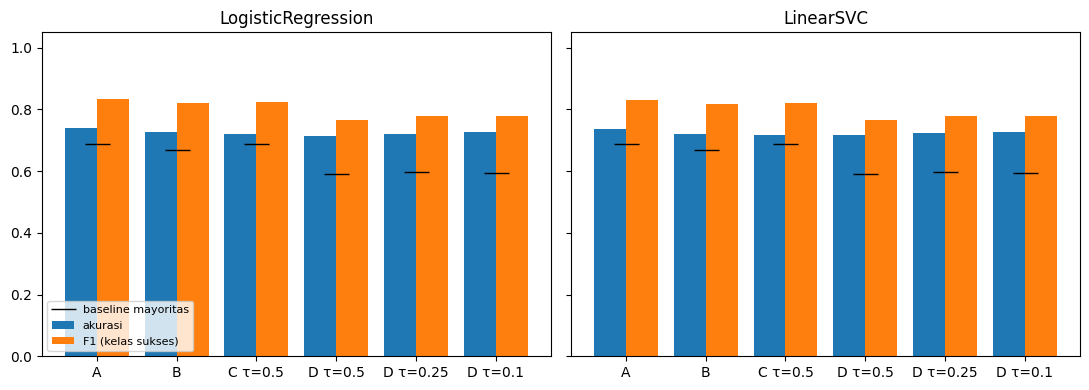

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model in zip(axes, ["LogisticRegression", "LinearSVC"]):
    sub = RES[RES.model == model]
    x = range(len(sub))
    ax.bar(x, sub["akurasi"], width=0.4, label="akurasi")
    ax.bar([i + 0.4 for i in x], sub["f1"], width=0.4, label="F1 (kelas sukses)")
    ax.plot([i + 0.2 for i in x], sub["baseline_mayoritas"], "k_", ms=18, label="baseline mayoritas")
    ax.set_xticks([i + 0.2 for i in x])
    ax.set_xticklabels([c.split(".")[0] + (" τ=" + c.split("τ=")[1].rstrip(")") if "τ=" in c else "") for c in sub["konfigurasi"]], rotation=0)
    ax.set_title(model); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ablasi.png", dpi=150); plt.show()

fraksi=0.25 n=103,576 total=67.7s (fitur 40.5s, sisanya 27.2s)
fraksi=0.50 n=207,500 total=106.1s (fitur 59.4s, sisanya 46.7s)
fraksi=0.75 n=310,715 total=130.9s (fitur 85.8s, sisanya 45.1s)
fraksi=1.00 n=413,778 total=182.8s (fitur 113.2s, sisanya 69.6s)
 fraksi  n_ulasan  waktu_fitur_s  waktu_dedup_fig_latih_s  waktu_total_s  dedup_s  fig_s  latih_eval_s
   0.25    103576          40.46                    27.24          67.70     7.39   0.92         18.66
   0.50    207500          59.40                    46.66         106.06    15.26   1.06         30.06
   0.75    310715          85.79                    45.11         130.91    23.21   1.79         19.56
   1.00    413778         113.23                    69.57         182.81    31.10   1.48         36.47

Rasio waktu 100% vs 50% data: 1.72x  (artikel: 256/156 = 1.64x untuk 9→18 GB)


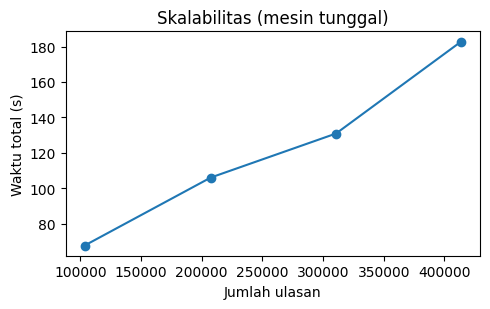

In [14]:
SCAL = []
if RUN_SCALABILITY:
    for frac in SCAL_FRACS:
        spark.catalog.clearCache()
        sub = df.sample(False, frac, SEED) if frac < 1.0 else df
        t0 = time.perf_counter()
        dsub, n_sub = build_features(sub)
        t_feat = time.perf_counter() - t0
        t1 = time.perf_counter()
        res, info, times, _ = run_config(f"skala {frac}", dsub, True, FIG_THRESHOLDS[0], True)
        t_rest = time.perf_counter() - t1
        SCAL.append({"fraksi": frac, "n_ulasan": n_sub, "waktu_fitur_s": t_feat,
                     "waktu_dedup_fig_latih_s": t_rest, "waktu_total_s": t_feat + t_rest,
                     **{k: v for k, v in times.items()}})
        print(f"fraksi={frac:.2f} n={n_sub:,} total={t_feat + t_rest:.1f}s (fitur {t_feat:.1f}s, sisanya {t_rest:.1f}s)")
        dsub.unpersist()
    SCAL_DF = pd.DataFrame(SCAL)
    print(SCAL_DF.round(2).to_string(index=False))
    # rasio saat data digandakan (mis. 0.5 -> 1.0); artikel: 256/156 = 1.64
    f_map = {r["fraksi"]: r["waktu_total_s"] for r in SCAL}
    if 0.5 in f_map and 1.0 in f_map:
        print(f"\nRasio waktu 100% vs 50% data: {f_map[1.0]/f_map[0.5]:.2f}x  (artikel: 256/156 = {256/156:.2f}x untuk 9→18 GB)")
    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.plot(SCAL_DF["n_ulasan"], SCAL_DF["waktu_total_s"], "o-")
    ax.set_xlabel("Jumlah ulasan"); ax.set_ylabel("Waktu total (s)"); ax.set_title("Skalabilitas (mesin tunggal)")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_skalabilitas.png", dpi=150); plt.show()
else:
    SCAL_DF = pd.DataFrame()
    print("RUN_SCALABILITY=False, dilewati.")

In [15]:
ART = {"akurasi_SVM_DMRDF": 0.954, "waktu_9GB_s": 156, "waktu_18GB_s": 256, "rasio_waktu_2x": 256 / 156}
best = RES[(RES.model == "LinearSVC") & RES.konfigurasi.str.startswith("D")].sort_values("akurasi", ascending=False)
rows = []
if len(best):
    b = best.iloc[0]
    rows.append(("Akurasi SVM + DMRDF", f"{ART['akurasi_SVM_DMRDF']:.3f}", f"{b['akurasi']:.3f} ({b['konfigurasi']})"))
    rows.append(("Baseline mayoritas (hanya data kita)", "tidak dilaporkan", f"{b['baseline_mayoritas']:.3f}"))
    rows.append(("Selisih akurasi terhadap baseline", "tidak dapat dihitung", f"{b['akurasi'] - b['baseline_mayoritas']:+.3f}"))
if RUN_SCALABILITY and len(SCAL_DF):
    fm = {r["fraksi"]: r["waktu_total_s"] for r in SCAL}
    if 0.5 in fm and 1.0 in fm:
        rows.append(("Rasio waktu saat data 2x", f"{ART['rasio_waktu_2x']:.2f}x", f"{fm[1.0]/fm[0.5]:.2f}x"))
COMPARE = pd.DataFrame(rows, columns=["Metrik", "Artikel", "Replikasi ini"])
print(COMPARE.to_string(index=False))

                              Metrik              Artikel                Replikasi ini
                 Akurasi SVM + DMRDF                0.954 0.728 (D. DMRDF+FIG (τ=0.1))
Baseline mayoritas (hanya data kita)     tidak dilaporkan                        0.593
   Selisih akurasi terhadap baseline tidak dapat dihitung                       +0.135
            Rasio waktu saat data 2x                1.64x                        1.72x


In [16]:
DEVIASI = [
    "Dataset setara (Kaggle Amazon Unlocked Mobile Phones), bukan dataset tertutup 7 merek/24 bulan milik artikel.",
    "Spark mode lokal pada satu mesin Colab, bukan klaster AWS; versi modern menggantikan Spark 2.2.1/PySpark 2.1.2.",
    f"Label sukses = rating >= {SUCCESS_RATING} pada tingkat ulasan (artikel tidak mendefinisikan label).",
    "Pers. (3) memakai log2|E_f| (artikel: log2 E_f, tak terdefinisi karena E_f <= 0 menurut Pers. 2).",
    "|ΔG| dinormalisasi ke [0,1] sebelum diberi ambang; ambang 0.5 artikel diuji bersama 0.25 dan 0.1.",
    "Skor δ (Pers. 5) diinterpretasikan sebagai bobot aspek signifikan ternormalisasi; ulasan dengan δ=0 dibuang.",
    "Dedup memakai kunci (produk, teks ternormalisasi) karena tidak ada ID pelanggan pada data.",
    "FIG dihitung hanya pada data latih (mencegah kebocoran label karena rating dipakai di FIG).",
    "SVM = LinearSVC (MLlib); polaritas dari SentiWordNet dengan negasi sederhana; daftar aspek rancangan sendiri.",
]
RESULT = {
    "env": ENV, "config": {"seed": SEED, "sample_frac": SAMPLE_FRAC, "train_frac": TRAIN_FRAC, "success_rating": SUCCESS_RATING,
                           "fig_thresholds": FIG_THRESHOLDS, "n_partitions": N_PARTITIONS, "aspects": ASPECT_NAMES},
    "data": STATS, "feature_time_full_s": T_FEAT_FULL, "config_info": CONFIG_INFO, "stage_times": STAGE_TIMES,
    "results": json.loads(RES.to_json(orient="records")),
    "scalability": json.loads(SCAL_DF.to_json(orient="records")) if len(SCAL_DF) else [],
    "article_reference": ART, "deviations": DEVIASI,
    "notebook_wall_time_s": time.perf_counter() - T_NOTEBOOK_START,
}
with open(f"{OUT_DIR}/hasil.json", "w") as f:
    json.dump(RESULT, f, indent=2, default=str)
RES.to_csv(f"{OUT_DIR}/hasil_ablasi.csv", index=False)
for tag, ft in FIG_TABLES.items():
    ft.to_csv(f"{OUT_DIR}/fig_{re.sub(r'[^A-Za-z0-9]+', '_', tag)}.csv", index=False)
if len(SCAL_DF):
    SCAL_DF.to_csv(f"{OUT_DIR}/skalabilitas.csv", index=False)
COMPARE.to_csv(f"{OUT_DIR}/perbandingan_artikel.csv", index=False)

print("=" * 70); print("RINGKASAN UNTUK LAPORAN"); print("=" * 70)
print(json.dumps(ENV, indent=1))
print(f"\nData: {STATS['n_raw']:,} baris mentah -> {STATS['n_used']:,} dipakai | proporsi sukses {STATS['p_success']:.4f}")
print("\nAblasi:\n", RES[cols_show].round(4).to_string(index=False))
print("\nPerbandingan artikel:\n", COMPARE.to_string(index=False))
print("\nDeviasi:"); [print(" -", d) for d in DEVIASI]
print(f"\nTotal waktu notebook: {RESULT['notebook_wall_time_s']/60:.1f} menit")

shutil.make_archive("/content/hasil_eksperimen" if os.path.isdir("/content") else "hasil_eksperimen", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("/content/hasil_eksperimen.zip")
except Exception as e:
    print("Unduhan otomatis hanya di Colab; zip ada di", OUT_DIR + ".zip")

RINGKASAN UNTUK LAPORAN
{
 "python": "3.13.16",
 "pyspark": "4.0.4",
 "spark": "4.0.4",
 "java": "openjdk version \"21.0.12.1\" 2026-08-18",
 "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
 "cpu_cores": 2,
 "ram_gb": 12.7,
 "driver_memory": "7g",
 "master": "local[*]",
 "seed": 42
}

Data: 413,840 baris mentah -> 413,778 dipakai | proporsi sukses 0.6887

Ablasi:
           konfigurasi              model  n_latih  n_uji  n_fitur  akurasi  presisi  recall     f1    auc  baseline_mayoritas
   A. Tanpa DMRDF/FIG LogisticRegression   310497 103281       32   0.7399   0.7466  0.9416 0.8329 0.7314              0.6881
   A. Tanpa DMRDF/FIG          LinearSVC   310497 103281       32   0.7375   0.7495  0.9290 0.8297 0.7309              0.6881
        B. Dedup saja LogisticRegression   244948  81611       32   0.7278   0.7326  0.9331 0.8208 0.7300              0.6680
        B. Dedup saja          LinearSVC   244948  81611       32   0.7214   0.7297  0.9261 0.8162 0.7290              0.6680
  C. 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>